# Phân loại thể loại nhạc

Notebook gồm các phần:
1. Đọc và chuẩn bị dữ liệu
2. Huấn luyện 9 mô hình và xuất file nộp bài
3. Vẽ hình minh họa cho báo cáo

## Phần 1. Đọc và chuẩn bị dữ liệu

In [4]:
# Nạp các thư viện cơ bản
import numpy as np
import pandas as pd

In [5]:
# Khai báo đường dẫn tới 3 file dữ liệu trên Kaggle
path_train = '../input/competitions/shai-music-genre-classification/train (1).csv'
path_test = '../input/competitions/shai-music-genre-classification/test (2).csv'
path_sub = '../input/competitions/shai-music-genre-classification/sample_submission (2).csv'

In [6]:
# Đọc 3 file csv thành DataFrame
df_train = pd.read_csv(path_train)
df_test = pd.read_csv(path_test)
df_sub = pd.read_csv(path_sub)

In [7]:
# In danh sách tên cột của tập train
print("Danh sách các cột trong tập Train:")
print(df_train.columns.tolist())

Danh sách các cột trong tập Train:
['Id', 'Artist Name', 'Track Name', 'Popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_in min/ms', 'time_signature', 'Class']


In [8]:
# Xem 5 dòng đầu của tập train
display(df_train.head(5))

,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [9]:
# Xem kích thước các tập dữ liệu
print("Kích thước tập Train:", df_train.shape)
print("Kích thước tập Test:", df_test.shape)
print("Kích thước file mẫu nộp bài:", df_sub.shape)

Kích thước tập Train: (14396, 18)
Kích thước tập Test: (3600, 17)
Kích thước file mẫu nộp bài: (3600, 2)


In [10]:
# Đếm số giá trị thiếu ở mỗi cột của tập train
print(df_train.isna().sum())

Id                       0
Artist Name              0
Track Name               0
Popularity             333
danceability             0
energy                   0
key                   1609
loudness                 0
mode                     0
speechiness              0
acousticness             0
instrumentalness      3541
liveness                 0
valence                  0
tempo                    0
duration_in min/ms       0
time_signature           0
Class                    0
dtype: int64


In [11]:
# Khai báo tên cột nhãn và tên cột Id
ten_cot_nhan = 'Class'
ten_cot_id = 'Id'

In [12]:
# Tách tập train thành X là đặc trưng và y là nhãn
# Bỏ cột Class vì đó là nhãn cần dự đoán
# Bỏ cột Id vì Id không giúp ích cho việc dự đoán
X = df_train.drop(columns=[ten_cot_nhan, ten_cot_id])
y = df_train[ten_cot_nhan]

In [13]:
# Chuẩn bị tập test
# Giữ lại cột Id để ghép vào file nộp bài
test_ids = df_test[ten_cot_id]

# Bỏ cột Id khỏi tập test
test_X = df_test.drop(columns=[ten_cot_id])

# Sắp xếp cột của test giống hệt cột của train
test_X = test_X[X.columns]

In [14]:
# In kích thước để kiểm tra
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)
print("Kích thước test_X:", test_X.shape)
print("Các cột đặc trưng:")
print(X.columns.tolist())

Kích thước X: (14396, 16)
Kích thước y: (14396,)
Kích thước test_X: (3600, 16)
Các cột đặc trưng:
['Artist Name', 'Track Name', 'Popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_in min/ms', 'time_signature']


In [15]:
# Bỏ 2 cột dạng chữ vì mô hình chỉ nhận số
cot_bo_qua = ['Artist Name', 'Track Name']
X_num = X.drop(columns=cot_bo_qua)
test_X_num = test_X.drop(columns=cot_bo_qua)

print("Các cột số được giữ lại:")
print(X_num.columns.tolist())

Các cột số được giữ lại:
['Popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_in min/ms', 'time_signature']


In [16]:
# Mã hóa nhãn y thành số nguyên
from sklearn.preprocessing import LabelEncoder

bo_ma_hoa_nhan = LabelEncoder()
y_encoded = bo_ma_hoa_nhan.fit_transform(y)

print("10 nhãn đầu tiên sau khi mã hóa:")
print(y_encoded[:10])

10 nhãn đầu tiên sau khi mã hóa:
[ 9  6 10  2  5 10  0  8 10  5]


In [17]:
# Điền giá trị thiếu bằng 0 cho cả train và test
X_num_clean = X_num.fillna(0)
test_X_num_clean = test_X_num.fillna(0)

print("Kích thước dữ liệu sạch:", X_num_clean.shape)
print("Số giá trị thiếu còn lại:", X_num_clean.isna().sum().sum())

Kích thước dữ liệu sạch: (14396, 14)
Số giá trị thiếu còn lại: 0


In [18]:
# Chia tập train thành 80% để học và 20% để kiểm tra
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_tr, X_val, y_tr, y_val = train_test_split(
    X_num_clean,
    y_encoded,
    test_size=0.2,
    random_state=42
)

print("Kích thước X_tr:", X_tr.shape)
print("Kích thước X_val:", X_val.shape)

Kích thước X_tr: (11516, 14)
Kích thước X_val: (2880, 14)


## Phần 2. Huấn luyện các mô hình

### 2.1. Random Forest

In [19]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(random_state=42)

In [20]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Random Forest...")
model_rf.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Random Forest...
Huấn luyện xong


In [21]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_rf = model_rf.predict(X_val)
acc_model_rf = accuracy_score(y_val, y_pred_model_rf)
print(f"Độ chính xác của Random Forest trên tập Validation: {acc_model_rf * 100:.2f}%")

Độ chính xác của Random Forest trên tập Validation: 51.32%


In [22]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Random Forest trên toàn bộ dữ liệu...")
model_rf.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại Random Forest trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [23]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_rf.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_random_forest.csv', index=False)
print("Đã xuất file submission_random_forest.csv")

Đã xuất file submission_random_forest.csv


### 2.2. Decision Tree

In [24]:
# Nạp mô hình và khởi tạo
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)

In [25]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Decision Tree...")
model_dt.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Decision Tree...
Huấn luyện xong


In [26]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_dt = model_dt.predict(X_val)
acc_model_dt = accuracy_score(y_val, y_pred_model_dt)
print(f"Độ chính xác của Decision Tree trên tập Validation: {acc_model_dt * 100:.2f}%")

Độ chính xác của Decision Tree trên tập Validation: 36.70%


In [27]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Decision Tree trên toàn bộ dữ liệu...")
model_dt.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại Decision Tree trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [28]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_dt.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_decision_tree.csv', index=False)
print("Đã xuất file submission_decision_tree.csv")

Đã xuất file submission_decision_tree.csv


### 2.3. KNN

In [29]:
# Nạp mô hình và khởi tạo
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier(n_neighbors=5)

In [30]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện KNN...")
model_knn.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện KNN...
Huấn luyện xong


In [31]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_knn = model_knn.predict(X_val)
acc_model_knn = accuracy_score(y_val, y_pred_model_knn)
print(f"Độ chính xác của KNN trên tập Validation: {acc_model_knn * 100:.2f}%")

Độ chính xác của KNN trên tập Validation: 23.23%


In [32]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại KNN trên toàn bộ dữ liệu...")
model_knn.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại KNN trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [33]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_knn.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_knn.csv', index=False)
print("Đã xuất file submission_knn.csv")

Đã xuất file submission_knn.csv


### 2.4. Extra Trees

In [34]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import ExtraTreesClassifier

model_et = ExtraTreesClassifier(n_estimators=100, random_state=42)

In [35]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Extra Trees...")
model_et.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Extra Trees...
Huấn luyện xong


In [36]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_et = model_et.predict(X_val)
acc_model_et = accuracy_score(y_val, y_pred_model_et)
print(f"Độ chính xác của Extra Trees trên tập Validation: {acc_model_et * 100:.2f}%")

Độ chính xác của Extra Trees trên tập Validation: 50.21%


In [37]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Extra Trees trên toàn bộ dữ liệu...")
model_et.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại Extra Trees trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [38]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_et.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_extra_trees.csv', index=False)
print("Đã xuất file submission_extra_trees.csv")

Đã xuất file submission_extra_trees.csv


### 2.5. AdaBoost

In [39]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import AdaBoostClassifier

model_ada = AdaBoostClassifier(random_state=42)

In [40]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện AdaBoost...")
model_ada.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện AdaBoost...
Huấn luyện xong


In [41]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_ada = model_ada.predict(X_val)
acc_model_ada = accuracy_score(y_val, y_pred_model_ada)
print(f"Độ chính xác của AdaBoost trên tập Validation: {acc_model_ada * 100:.2f}%")

Độ chính xác của AdaBoost trên tập Validation: 26.81%


In [42]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại AdaBoost trên toàn bộ dữ liệu...")
model_ada.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại AdaBoost trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [43]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_ada.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_adaboost.csv', index=False)
print("Đã xuất file submission_adaboost.csv")

Đã xuất file submission_adaboost.csv


### 2.6. MLP Neural Network

In [44]:
# Nạp mô hình và khởi tạo
from sklearn.neural_network import MLPClassifier

model_mlp = MLPClassifier(random_state=42, max_iter=300)

In [45]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện MLP...")
model_mlp.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện MLP...
Huấn luyện xong


In [46]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_mlp = model_mlp.predict(X_val)
acc_model_mlp = accuracy_score(y_val, y_pred_model_mlp)
print(f"Độ chính xác của MLP trên tập Validation: {acc_model_mlp * 100:.2f}%")

Độ chính xác của MLP trên tập Validation: 21.15%


In [47]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại MLP trên toàn bộ dữ liệu...")
model_mlp.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại MLP trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [48]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_mlp.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_mlp.csv', index=False)
print("Đã xuất file submission_mlp.csv")

Đã xuất file submission_mlp.csv


### 2.7. Gradient Boosting

In [49]:
# Nạp mô hình và khởi tạo
from sklearn.ensemble import GradientBoostingClassifier

model_gb = GradientBoostingClassifier(random_state=42)

In [50]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Gradient Boosting...")
model_gb.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Gradient Boosting...
Huấn luyện xong


In [51]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_gb = model_gb.predict(X_val)
acc_model_gb = accuracy_score(y_val, y_pred_model_gb)
print(f"Độ chính xác của Gradient Boosting trên tập Validation: {acc_model_gb * 100:.2f}%")

Độ chính xác của Gradient Boosting trên tập Validation: 54.62%


In [52]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Gradient Boosting trên toàn bộ dữ liệu...")
model_gb.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại Gradient Boosting trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [53]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_gb.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_gradient_boosting.csv', index=False)
print("Đã xuất file submission_gradient_boosting.csv")

Đã xuất file submission_gradient_boosting.csv


### 2.8. SVC

In [54]:
# Nạp mô hình và khởi tạo
from sklearn.svm import SVC

model_svc = SVC(random_state=42)

In [55]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện SVC...")
model_svc.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện SVC...
Huấn luyện xong


In [56]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_svc = model_svc.predict(X_val)
acc_model_svc = accuracy_score(y_val, y_pred_model_svc)
print(f"Độ chính xác của SVC trên tập Validation: {acc_model_svc * 100:.2f}%")

Độ chính xác của SVC trên tập Validation: 29.69%


In [57]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại SVC trên toàn bộ dữ liệu...")
model_svc.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại SVC trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [58]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_svc.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_svc.csv', index=False)
print("Đã xuất file submission_svc.csv")

Đã xuất file submission_svc.csv


### 2.9. Naive Bayes

In [59]:
# Nạp mô hình và khởi tạo
from sklearn.naive_bayes import GaussianNB

model_nb = GaussianNB()

In [60]:
# Huấn luyện trên 80% dữ liệu
print("Đang huấn luyện Naive Bayes...")
model_nb.fit(X_tr, y_tr)
print("Huấn luyện xong")

Đang huấn luyện Naive Bayes...
Huấn luyện xong


In [61]:
# Dự đoán trên tập validation và tính độ chính xác
y_pred_model_nb = model_nb.predict(X_val)
acc_model_nb = accuracy_score(y_val, y_pred_model_nb)
print(f"Độ chính xác của Naive Bayes trên tập Validation: {acc_model_nb * 100:.2f}%")

Độ chính xác của Naive Bayes trên tập Validation: 33.75%


In [62]:
# Huấn luyện lại trên toàn bộ dữ liệu train để dự đoán tập test
print("Đang huấn luyện lại Naive Bayes trên toàn bộ dữ liệu...")
model_nb.fit(X_num_clean, y_encoded)
print("Huấn luyện lại xong")

Đang huấn luyện lại Naive Bayes trên toàn bộ dữ liệu...
Huấn luyện lại xong


In [63]:
# Dự đoán tập test và lưu file nộp bài
y_test_pred = model_nb.predict(test_X_num_clean)

sub = pd.DataFrame({
    'Id': test_ids,
    'Class': y_test_pred
})

sub.to_csv('submission_naive_bayes.csv', index=False)
print("Đã xuất file submission_naive_bayes.csv")

Đã xuất file submission_naive_bayes.csv


## Phần 3. Vẽ hình minh họa cho báo cáo

Các hình được lưu vào thư mục `hinh_bao_cao` ở dạng PNG 300 dpi.

Lưu ý: các mô hình ở Phần 2 đã được huấn luyện lại trên toàn bộ dữ liệu nên đã nhìn thấy tập validation.
Vì vậy ở Phần 3 ta clone lại mô hình và chỉ huấn luyện trên 80% dữ liệu để đánh giá cho công bằng.

### 3.0. Thiết lập chung

In [64]:
# Nạp các thư viện vẽ hình và đánh giá
import os
import time
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import learning_curve

# Tắt các cảnh báo cho gọn màn hình
warnings.filterwarnings("ignore")

In [65]:
# Tạo thư mục chứa hình
THU_MUC = "hinh_bao_cao"
os.makedirs(THU_MUC, exist_ok=True)

# Chọn kiểu nền cho hình
sns.set_theme(style="whitegrid")

In [66]:
# Hàm lưu hình ra file PNG rồi hiển thị lên màn hình
def luu(fig, ten):
    fig.savefig(f"{THU_MUC}/{ten}.png", dpi=300, bbox_inches="tight")
    plt.show()

In [67]:
# Lấy tên các lớp và tên các đặc trưng để dùng khi vẽ
ten_lop = [str(c) for c in bo_ma_hoa_nhan.classes_]
feature_names = X_num_clean.columns.tolist()

print("Các lớp:", ten_lop)
print("Các đặc trưng:", feature_names)

Các lớp: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
Các đặc trưng: ['Popularity', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_in min/ms', 'time_signature']


### 3.1. Phân bố nhãn

In [68]:
# Đếm số bài hát của mỗi lớp
dem = pd.Series(y_encoded).value_counts().sort_index()
print(dem)

0      500
1     1098
2     1018
3      322
4      310
5     1157
6     2069
7      461
8     1483
9     2019
10    3959
Name: count, dtype: int64


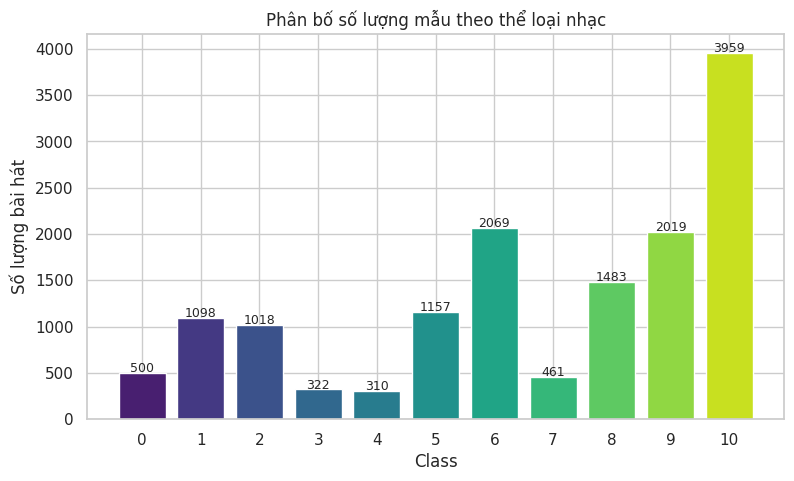

In [69]:
# Vẽ biểu đồ cột số lượng mẫu theo lớp
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar([ten_lop[i] for i in dem.index], dem.values,
              color=sns.color_palette("viridis", len(dem)))

# Ghi số lượng lên đầu mỗi cột
for b in bars:
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 10,
            int(b.get_height()), ha="center", fontsize=9)

ax.set_title("Phân bố số lượng mẫu theo thể loại nhạc")
ax.set_xlabel("Class")
ax.set_ylabel("Số lượng bài hát")
luu(fig, "01_phan_bo_nhan")

### 3.2. Tỷ lệ giá trị thiếu

In [70]:
# Tính phần trăm giá trị thiếu của từng cột trước khi điền 0
thieu = (X_num.isna().mean() * 100).sort_values(ascending=False)

# Chỉ giữ cột có thiếu dữ liệu
thieu = thieu[thieu > 0]
print(thieu)

instrumentalness    24.597110
key                 11.176716
Popularity           2.313143
dtype: float64


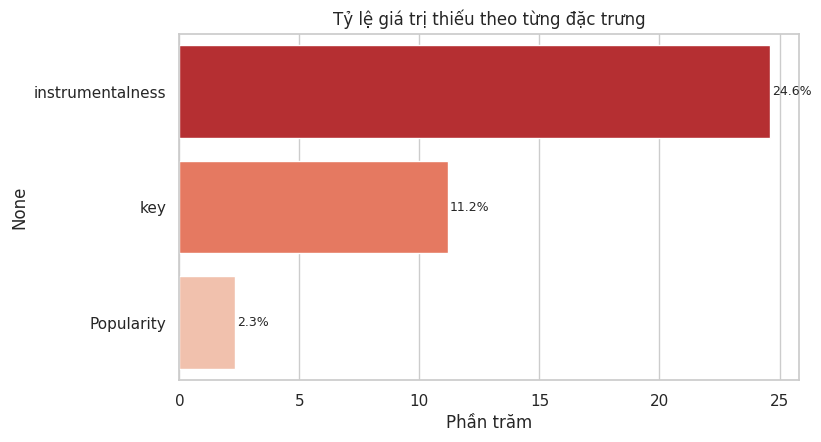

In [71]:
# Vẽ biểu đồ cột ngang tỷ lệ thiếu
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=thieu.values, y=thieu.index, palette="Reds_r", ax=ax)

# Ghi phần trăm cạnh mỗi cột
for i, v in enumerate(thieu.values):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9)

ax.set_title("Tỷ lệ giá trị thiếu theo từng đặc trưng")
ax.set_xlabel("Phần trăm")
luu(fig, "02_ty_le_thieu")

### 3.3. Ma trận tương quan

In [72]:
# Tính ma trận tương quan giữa các đặc trưng
corr = X_num_clean.corr()

# Tạo mặt nạ để chỉ vẽ nửa tam giác dưới
mask = np.triu(np.ones_like(corr, dtype=bool))

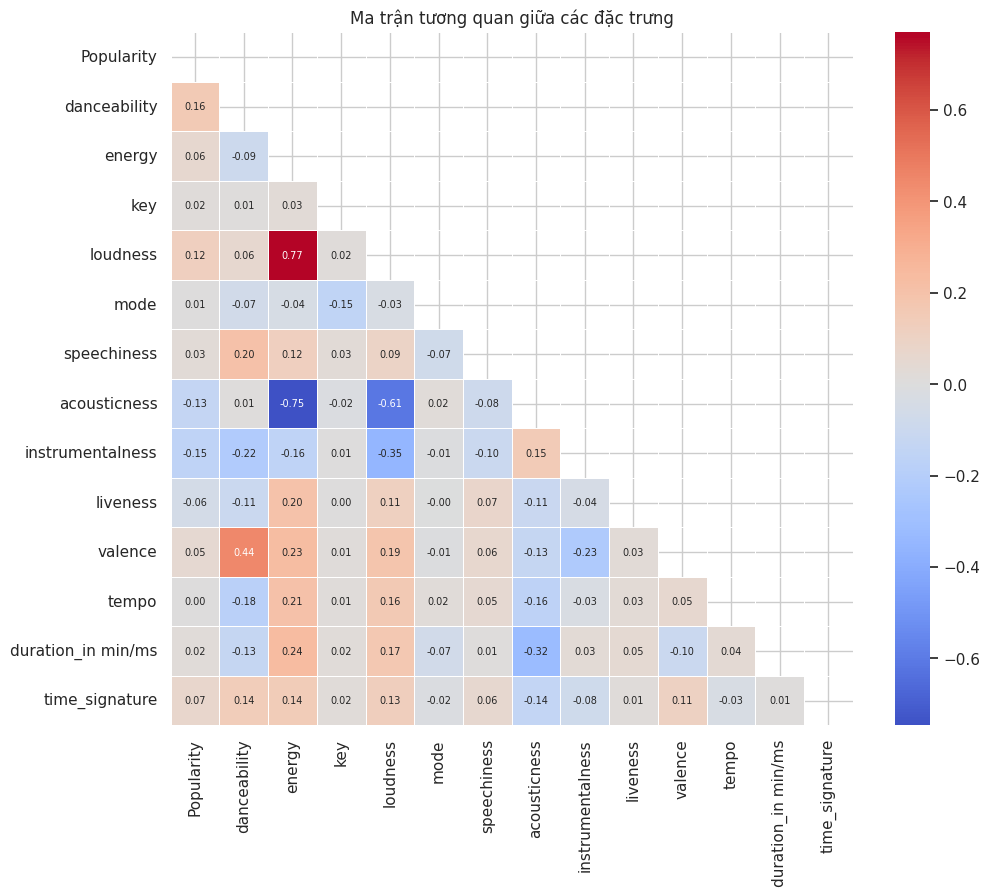

In [73]:
# Vẽ heatmap tương quan
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, annot_kws={"size": 7}, ax=ax)
ax.set_title("Ma trận tương quan giữa các đặc trưng")
luu(fig, "03_tuong_quan")

### 3.4. Phân phối các đặc trưng

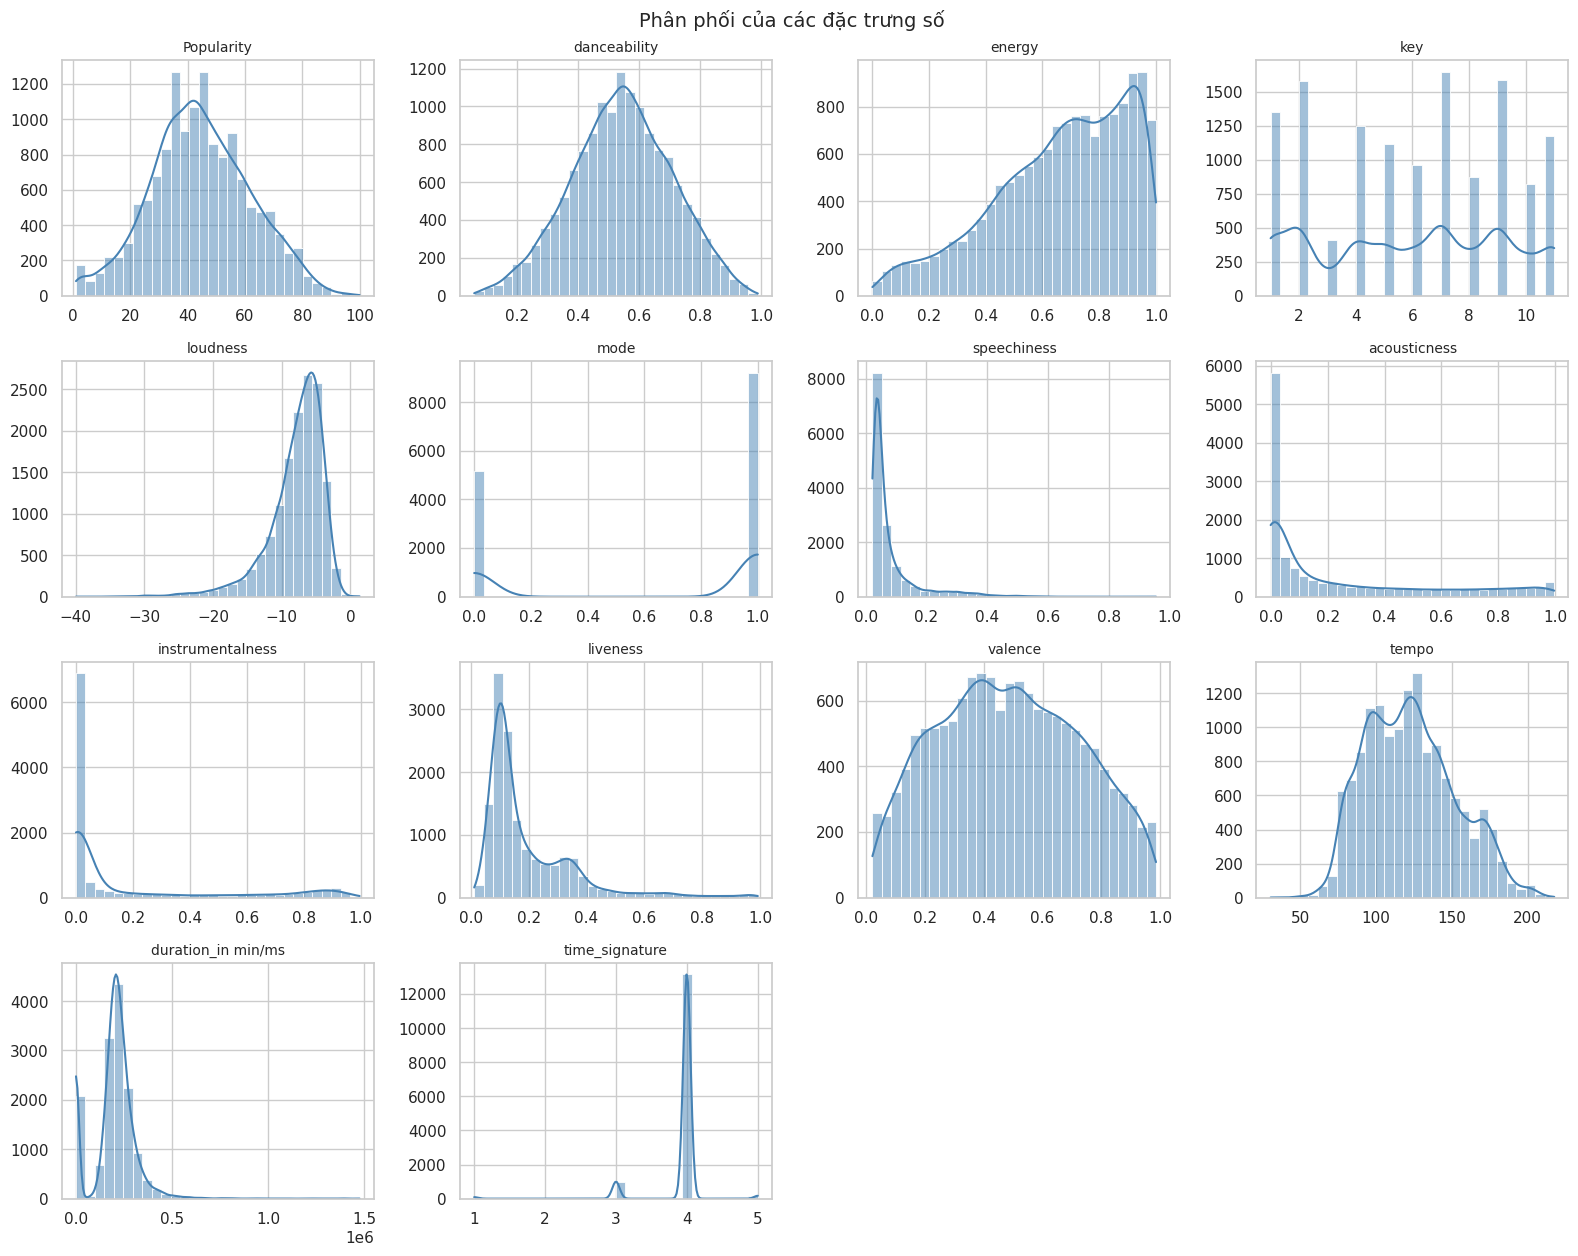

In [74]:
# Vẽ histogram cho từng đặc trưng
n_cot = 4
n_hang = int(np.ceil(len(feature_names) / n_cot))

fig, axes = plt.subplots(n_hang, n_cot, figsize=(16, 3.2 * n_hang))

for ax, c in zip(axes.ravel(), feature_names):
    sns.histplot(X_num[c].dropna(), bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")

# Tắt các ô trống còn thừa
for ax in axes.ravel()[len(feature_names):]:
    ax.axis("off")

fig.suptitle("Phân phối của các đặc trưng số", fontsize=14)
fig.tight_layout()
luu(fig, "04_phan_phoi_dac_trung")

### 3.5. Boxplot một số đặc trưng theo Class

In [75]:
# Chọn một số đặc trưng tiêu biểu
chon = ["energy", "danceability", "acousticness", "loudness", "valence", "Popularity"]

# Tạo bảng gồm các đặc trưng đã chọn và nhãn
df_box = X_num_clean[chon].copy()
df_box["Class"] = [ten_lop[i] for i in y_encoded]

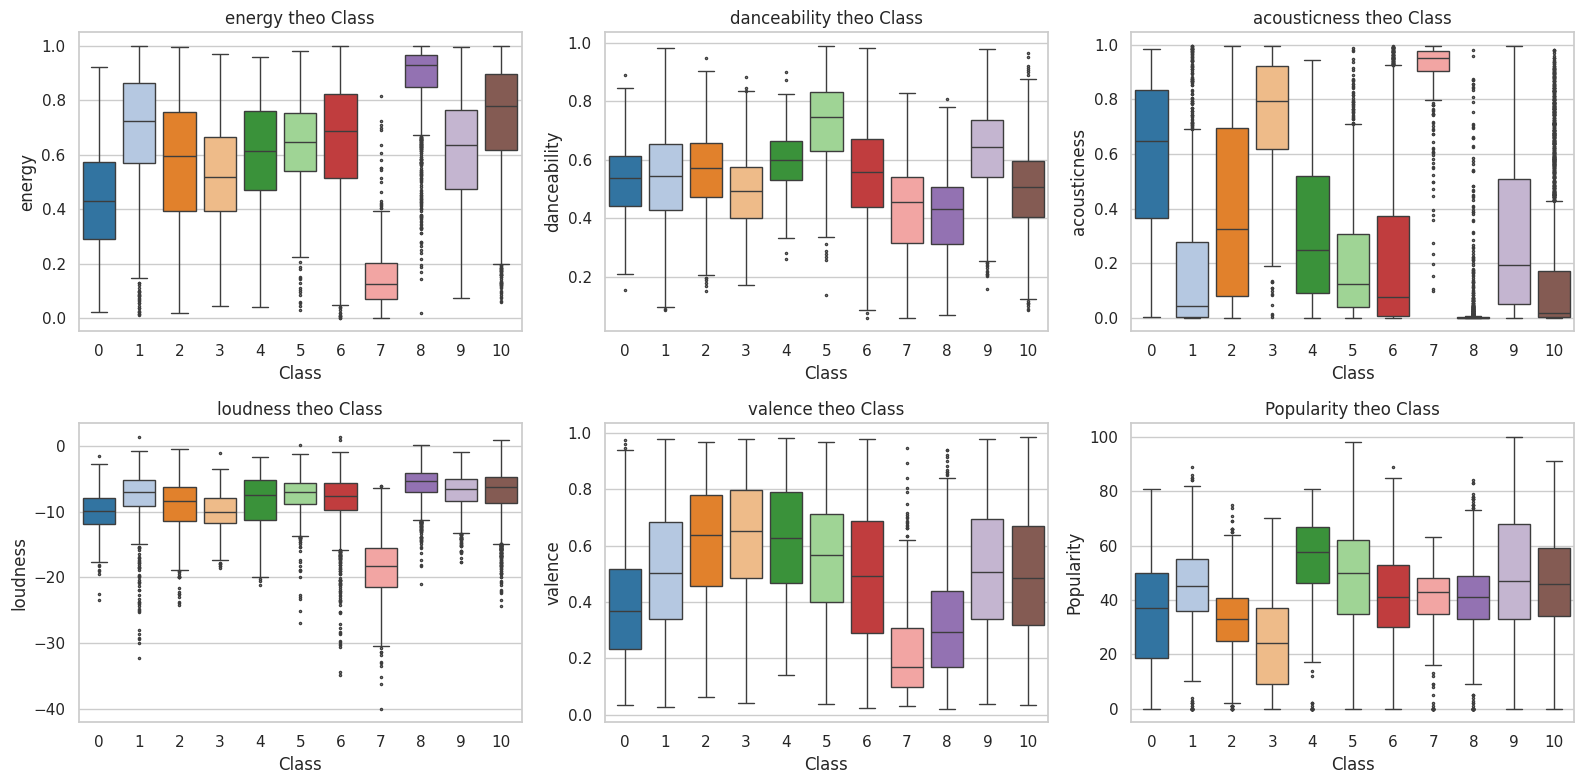

In [76]:
# Vẽ boxplot cho từng đặc trưng
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, c in zip(axes.ravel(), chon):
    sns.boxplot(data=df_box, x="Class", y=c, palette="tab20",
                order=ten_lop, fliersize=1.5, ax=ax)
    ax.set_title(f"{c} theo Class")

fig.tight_layout()
luu(fig, "05_boxplot_theo_class")

### 3.6. Huấn luyện lại các mô hình chỉ trên 80% dữ liệu

In [77]:
# Gom các mô hình đã tạo ở Phần 2 vào một dict
goc = {
    "Random Forest": model_rf,
    "Extra Trees": model_et,
    "Decision Tree": model_dt,
    "AdaBoost": model_ada,
    "KNN": model_knn,
    "MLP": model_mlp,
    "Gradient Boosting": model_gb,
    "SVC": model_svc,
    "Naive Bayes": model_nb,
}

In [78]:
# Dict lưu kết quả của từng mô hình
KQ = {}

for ten, m in goc.items():
    # Clone để có mô hình mới cùng tham số, chưa huấn luyện
    mo = clone(m)

    # Đo thời gian huấn luyện
    t0 = time.time()
    mo.fit(X_tr, y_tr)
    thoi_gian = time.time() - t0

    # Dự đoán trên tập train và tập validation
    pred_val = mo.predict(X_val)
    pred_tr = mo.predict(X_tr)

    # Lưu kết quả
    KQ[ten] = {
        "model": mo,
        "pred": pred_val,
        "acc_val": accuracy_score(y_val, pred_val),
        "acc_train": accuracy_score(y_tr, pred_tr),
        "time": thoi_gian,
    }

    print(f"{ten:15s} | Val = {KQ[ten]['acc_val']*100:6.2f}% | "
          f"Train = {KQ[ten]['acc_train']*100:6.2f}% | Thời gian = {thoi_gian:.2f}s")

Random Forest   | Val =  51.32% | Train =  93.81% | Thời gian = 5.38s
Extra Trees     | Val =  50.21% | Train =  93.81% | Thời gian = 2.38s
Decision Tree   | Val =  36.70% | Train =  93.81% | Thời gian = 0.33s
AdaBoost        | Val =  26.81% | Train =  27.33% | Thời gian = 1.16s
KNN             | Val =  23.23% | Train =  47.86% | Thời gian = 0.02s
MLP             | Val =  21.15% | Train =  21.51% | Thời gian = 1.11s
Gradient Boosting | Val =  54.62% | Train =  64.00% | Thời gian = 63.19s
SVC             | Val =  29.69% | Train =  30.05% | Thời gian = 8.96s
Naive Bayes     | Val =  33.75% | Train =  34.13% | Thời gian = 0.01s


In [79]:
# Sắp xếp mô hình theo accuracy validation giảm dần
thu_tu = sorted(KQ, key=lambda k: KQ[k]["acc_val"], reverse=True)
ten_tot_nhat = thu_tu[0]

print("Thứ tự các mô hình:", thu_tu)
print("Mô hình tốt nhất:", ten_tot_nhat)

Thứ tự các mô hình: ['Gradient Boosting', 'Random Forest', 'Extra Trees', 'Decision Tree', 'Naive Bayes', 'SVC', 'AdaBoost', 'KNN', 'MLP']
Mô hình tốt nhất: Gradient Boosting


### 3.7. So sánh độ chính xác giữa các mô hình

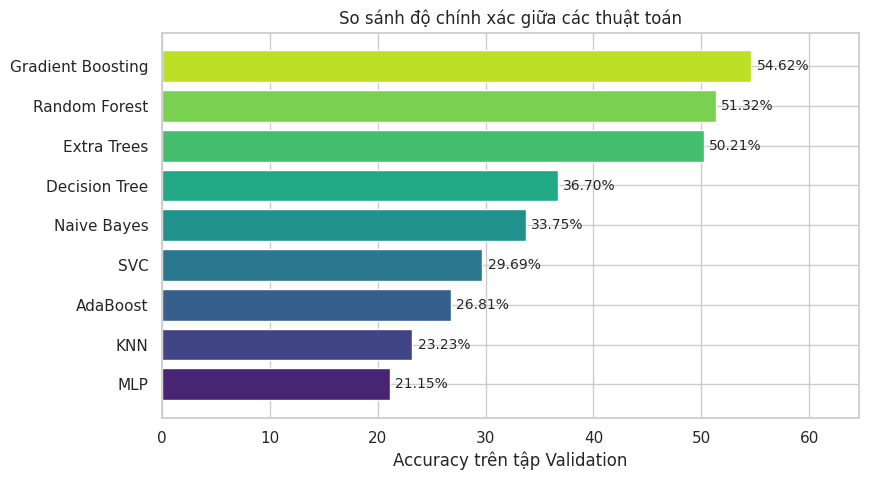

In [80]:
# Vẽ biểu đồ cột ngang so sánh accuracy
acc = [KQ[k]["acc_val"] * 100 for k in thu_tu]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(thu_tu[::-1], acc[::-1],
               color=sns.color_palette("viridis", len(thu_tu)))

# Ghi giá trị cạnh mỗi cột
for b in bars:
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.2f}%", va="center", fontsize=10)

ax.set_xlim(0, max(acc) + 10)
ax.set_xlabel("Accuracy trên tập Validation")
ax.set_title("So sánh độ chính xác giữa các thuật toán")
luu(fig, "07_so_sanh_accuracy")

### 3.8. So sánh Accuracy, Precision, Recall, F1

In [81]:
# Tính các chỉ số cho từng mô hình
rows = []
for k in thu_tu:
    p = KQ[k]["pred"]
    rows.append({
        "Mô hình": k,
        "Accuracy": accuracy_score(y_val, p),
        "Precision": precision_score(y_val, p, average="macro", zero_division=0),
        "Recall": recall_score(y_val, p, average="macro", zero_division=0),
        "F1": f1_score(y_val, p, average="macro", zero_division=0),
    })

df_metric = pd.DataFrame(rows).set_index("Mô hình")
df_metric = df_metric.round(4)
print(df_metric)

# Lưu bảng ra file csv để chèn vào báo cáo
df_metric.to_csv(f"{THU_MUC}/bang_so_sanh_chi_so.csv")

                   Accuracy  Precision  Recall      F1
Mô hình                                               
Gradient Boosting    0.5462     0.5883  0.5798  0.5757
Random Forest        0.5132     0.5941  0.5656  0.5720
Extra Trees          0.5021     0.5710  0.5500  0.5533
Decision Tree        0.3670     0.4622  0.4549  0.4570
Naive Bayes          0.3375     0.3664  0.3136  0.2618
SVC                  0.2969     0.0501  0.1788  0.0780
AdaBoost             0.2681     0.1613  0.1831  0.1365
KNN                  0.2323     0.2813  0.2836  0.2800
MLP                  0.2115     0.2940  0.2739  0.1934


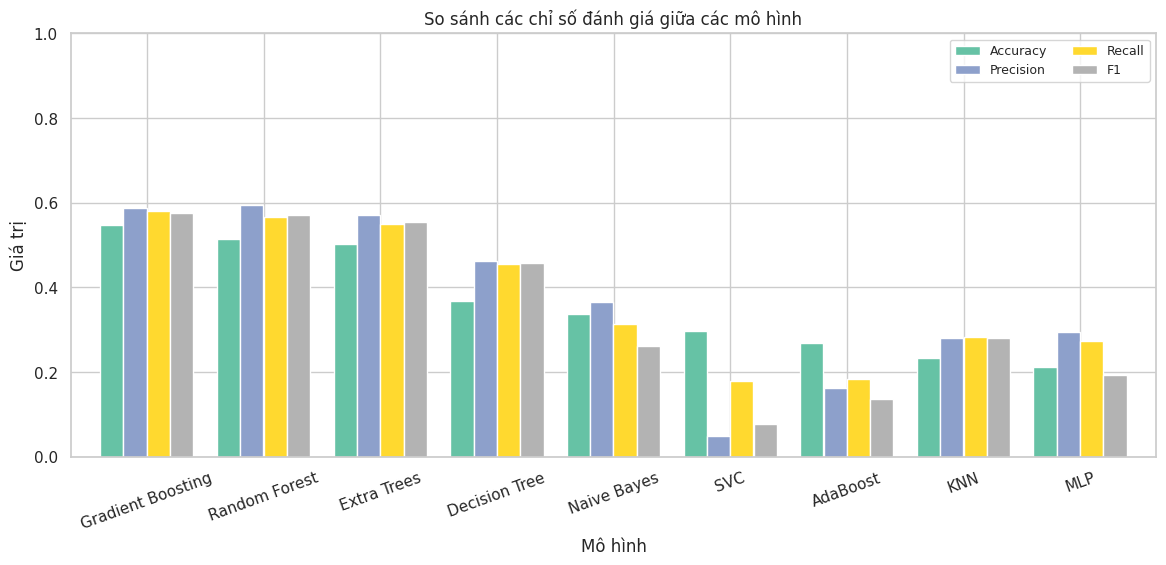

In [82]:
# Vẽ biểu đồ cột nhóm cho các chỉ số
fig, ax = plt.subplots(figsize=(14, 5.5))
df_metric.plot(kind="bar", ax=ax, colormap="Set2", width=0.8, edgecolor="white")
ax.set_ylim(0, 1)
ax.set_ylabel("Giá trị")
ax.set_title("So sánh các chỉ số đánh giá giữa các mô hình")
ax.legend(loc="upper right", ncol=2, fontsize=9)
plt.xticks(rotation=20)
luu(fig, "08_so_sanh_chi_so")

### 3.9. Ma trận nhầm lẫn

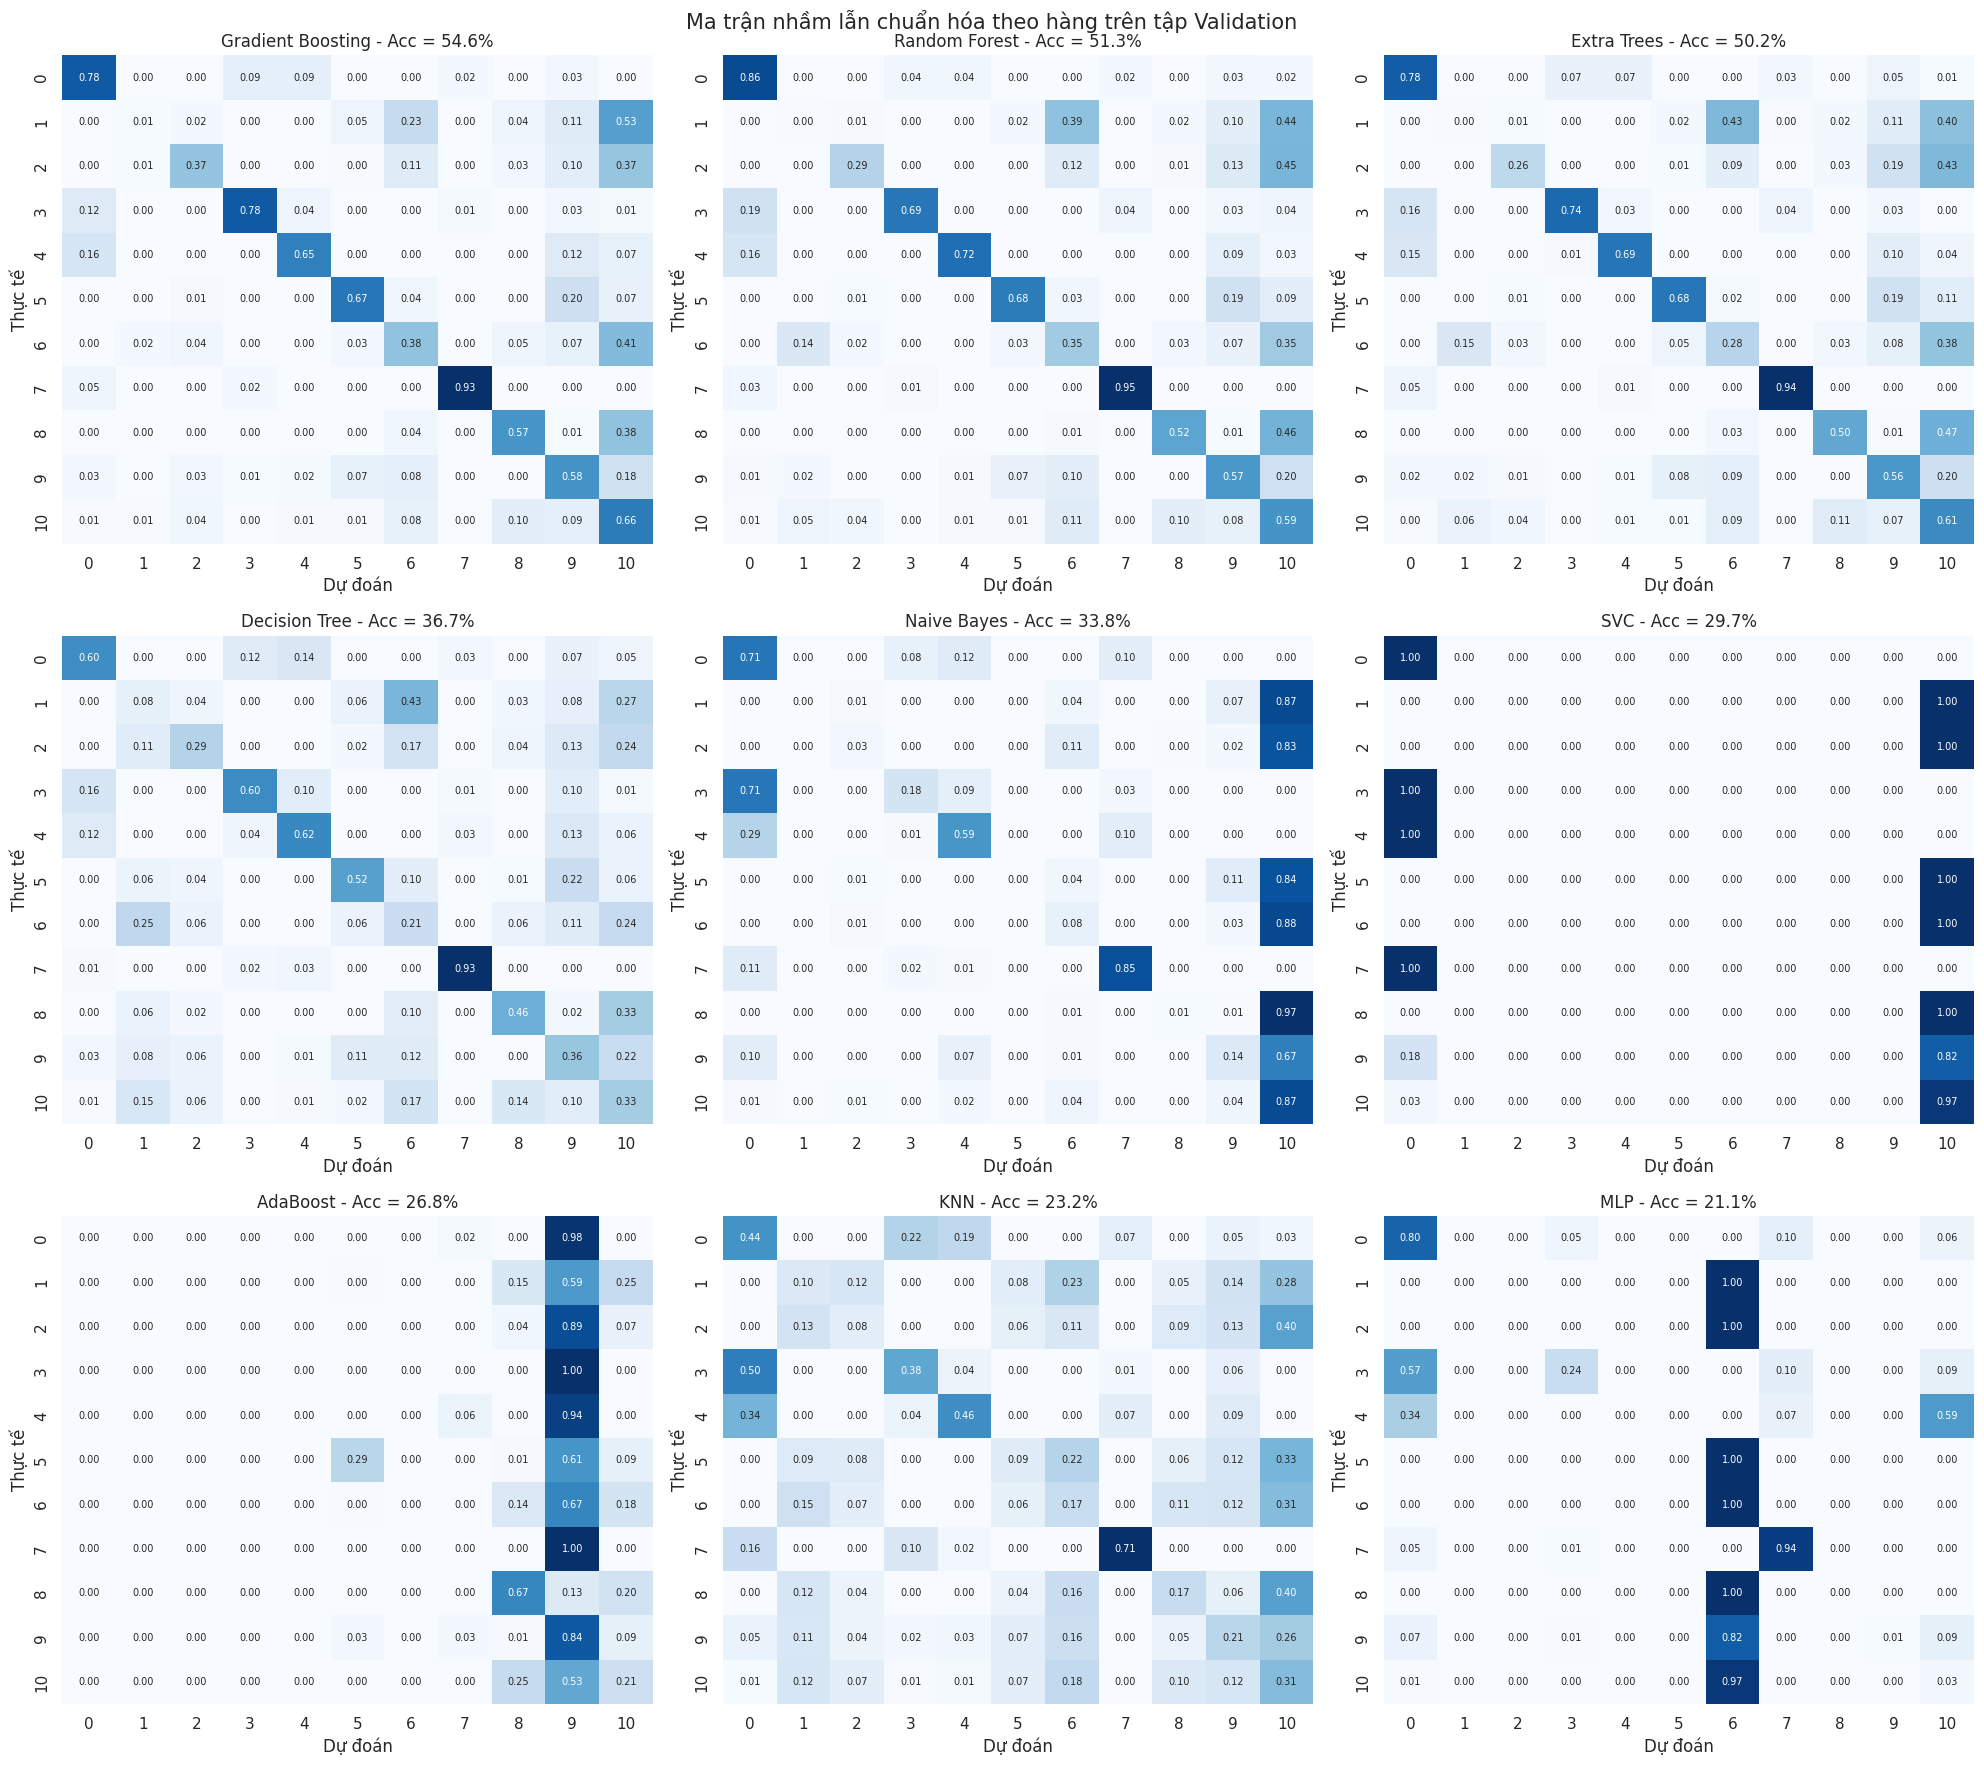

In [83]:
# Vẽ ma trận nhầm lẫn chuẩn hóa theo hàng cho cả 9 mô hình
fig, axes = plt.subplots(3, 3, figsize=(20, 18))

for ax, k in zip(axes.ravel(), thu_tu):
    cm = confusion_matrix(y_val, KQ[k]["pred"], labels=range(len(ten_lop)))

    # Chia mỗi hàng cho tổng hàng để ra tỷ lệ
    tong_hang = cm.sum(axis=1, keepdims=True)
    cm_n = cm / np.maximum(tong_hang, 1)

    sns.heatmap(cm_n, annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=ten_lop, yticklabels=ten_lop,
                annot_kws={"size": 7}, ax=ax)
    ax.set_title(f"{k} - Acc = {KQ[k]['acc_val']*100:.1f}%")
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")

fig.suptitle("Ma trận nhầm lẫn chuẩn hóa theo hàng trên tập Validation", fontsize=15)
fig.tight_layout()
luu(fig, "09_confusion_matrix_tat_ca")

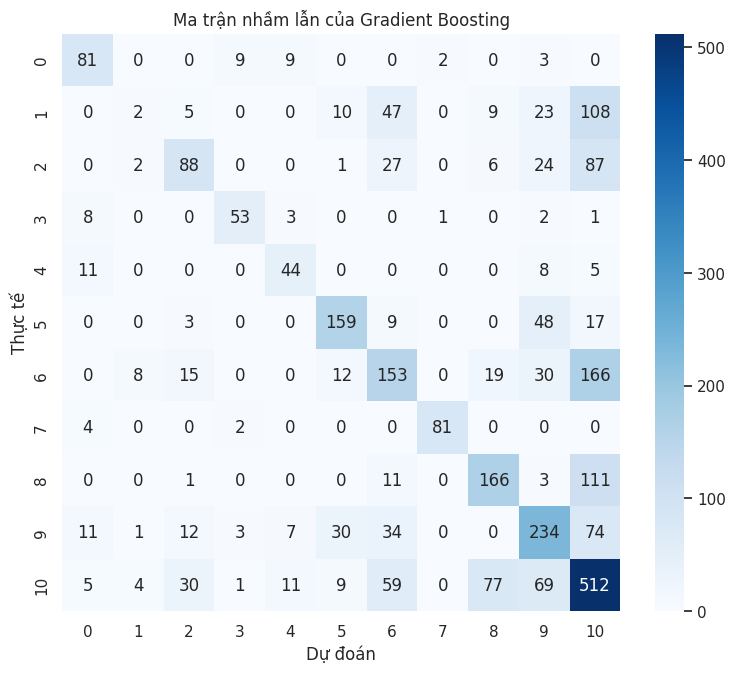

In [84]:
# Vẽ ma trận nhầm lẫn dạng số lượng cho mô hình tốt nhất
fig, ax = plt.subplots(figsize=(9, 7.5))
cm = confusion_matrix(y_val, KQ[ten_tot_nhat]["pred"], labels=range(len(ten_lop)))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=ten_lop, yticklabels=ten_lop, ax=ax)
ax.set_title(f"Ma trận nhầm lẫn của {ten_tot_nhat}")
ax.set_xlabel("Dự đoán")
ax.set_ylabel("Thực tế")
luu(fig, "09b_confusion_matrix_tot_nhat")

### 3.10. F1-score theo từng lớp

In [85]:
# Tính F1 của từng lớp cho từng mô hình
f1_lop = {}
for k in thu_tu:
    f1_lop[k] = f1_score(y_val, KQ[k]["pred"], average=None,
                         labels=range(len(ten_lop)), zero_division=0)

# Chuyển thành bảng, hàng là mô hình, cột là lớp
f1_lop = pd.DataFrame(f1_lop, index=ten_lop).T
print(f1_lop.round(2))

                      0     1     2     3     4     5     6     7     8     9  \
Gradient Boosting  0.72  0.02  0.45  0.78  0.62  0.70  0.41  0.95  0.58  0.55   
Random Forest      0.77  0.01  0.39  0.78  0.72  0.71  0.35  0.95  0.56  0.56   
Extra Trees        0.73  0.01  0.35  0.78  0.69  0.69  0.31  0.93  0.54  0.54   
Decision Tree      0.62  0.06  0.31  0.64  0.56  0.53  0.20  0.93  0.46  0.37   
Naive Bayes        0.48  0.00  0.05  0.26  0.46  0.00  0.12  0.82  0.02  0.20   
SVC                0.39  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00   
AdaBoost           0.00  0.00  0.00  0.00  0.00  0.42  0.00  0.00  0.50  0.30   
KNN                0.37  0.08  0.09  0.37  0.43  0.10  0.16  0.77  0.19  0.22   
MLP                0.58  0.00  0.00  0.34  0.00  0.00  0.28  0.85  0.00  0.02   

                     10  
Gradient Boosting  0.55  
Random Forest      0.50  
Extra Trees        0.52  
Decision Tree      0.35  
Naive Bayes        0.46  
SVC                0.46  
AdaBoos

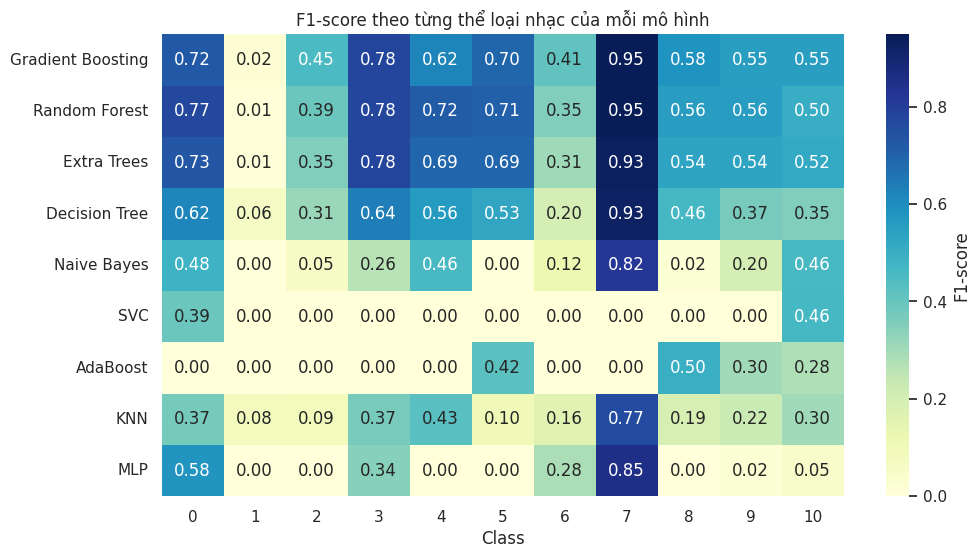

In [86]:
# Vẽ heatmap F1 theo lớp
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(f1_lop, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax,
            cbar_kws={"label": "F1-score"})
ax.set_xlabel("Class")
ax.set_ylabel("")
ax.set_title("F1-score theo từng thể loại nhạc của mỗi mô hình")
luu(fig, "10_f1_theo_lop")

### 3.11. So sánh Train và Validation để xem overfitting

In [87]:
# Lấy accuracy train và validation của từng mô hình
tr = [KQ[k]["acc_train"] * 100 for k in thu_tu]
va = [KQ[k]["acc_val"] * 100 for k in thu_tu]

x = np.arange(len(thu_tu))
w = 0.38

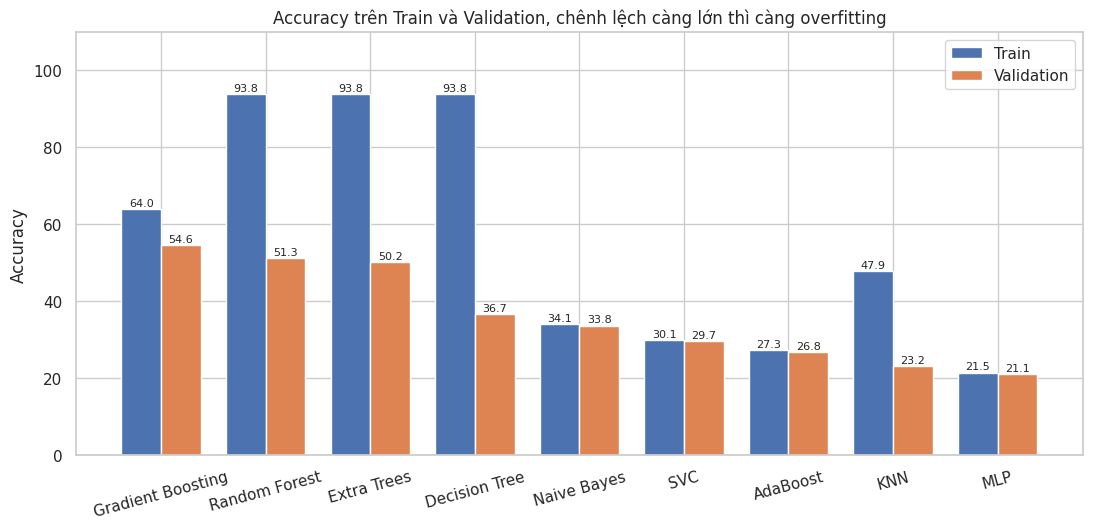

In [88]:
# Vẽ cột đôi Train và Validation
fig, ax = plt.subplots(figsize=(13, 5.5))
b1 = ax.bar(x - w / 2, tr, w, label="Train", color="#4C72B0")
b2 = ax.bar(x + w / 2, va, w, label="Validation", color="#DD8452")

# Ghi giá trị lên đầu cột
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8,
            f"{b.get_height():.1f}", ha="center", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(thu_tu, rotation=15)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 110)
ax.set_title("Accuracy trên Train và Validation, chênh lệch càng lớn thì càng overfitting")
ax.legend()
luu(fig, "11_train_vs_val")

### 3.12. Thời gian huấn luyện

In [89]:
# Lấy thời gian huấn luyện rồi sắp xếp tăng dần
tg = pd.Series({k: KQ[k]["time"] for k in KQ}).sort_values()
print(tg.round(2))

Naive Bayes           0.01
KNN                   0.02
Decision Tree         0.33
MLP                   1.11
AdaBoost              1.16
Extra Trees           2.38
Random Forest         5.38
SVC                   8.96
Gradient Boosting    63.19
dtype: float64


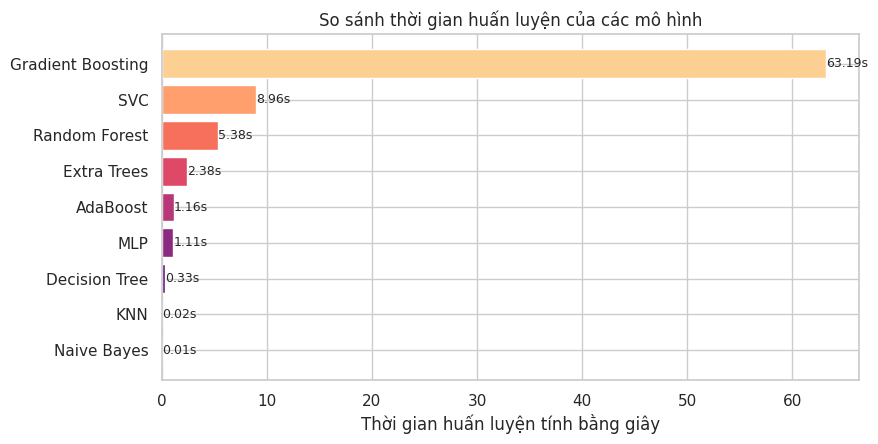

In [90]:
# Vẽ biểu đồ cột ngang thời gian huấn luyện
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(tg.index, tg.values, color=sns.color_palette("magma", len(tg)))

for b in bars:
    ax.text(b.get_width() + 0.02, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.2f}s", va="center", fontsize=9)

ax.set_xlabel("Thời gian huấn luyện tính bằng giây")
ax.set_title("So sánh thời gian huấn luyện của các mô hình")
luu(fig, "12_thoi_gian_huan_luyen")

### 3.13. Độ quan trọng của đặc trưng

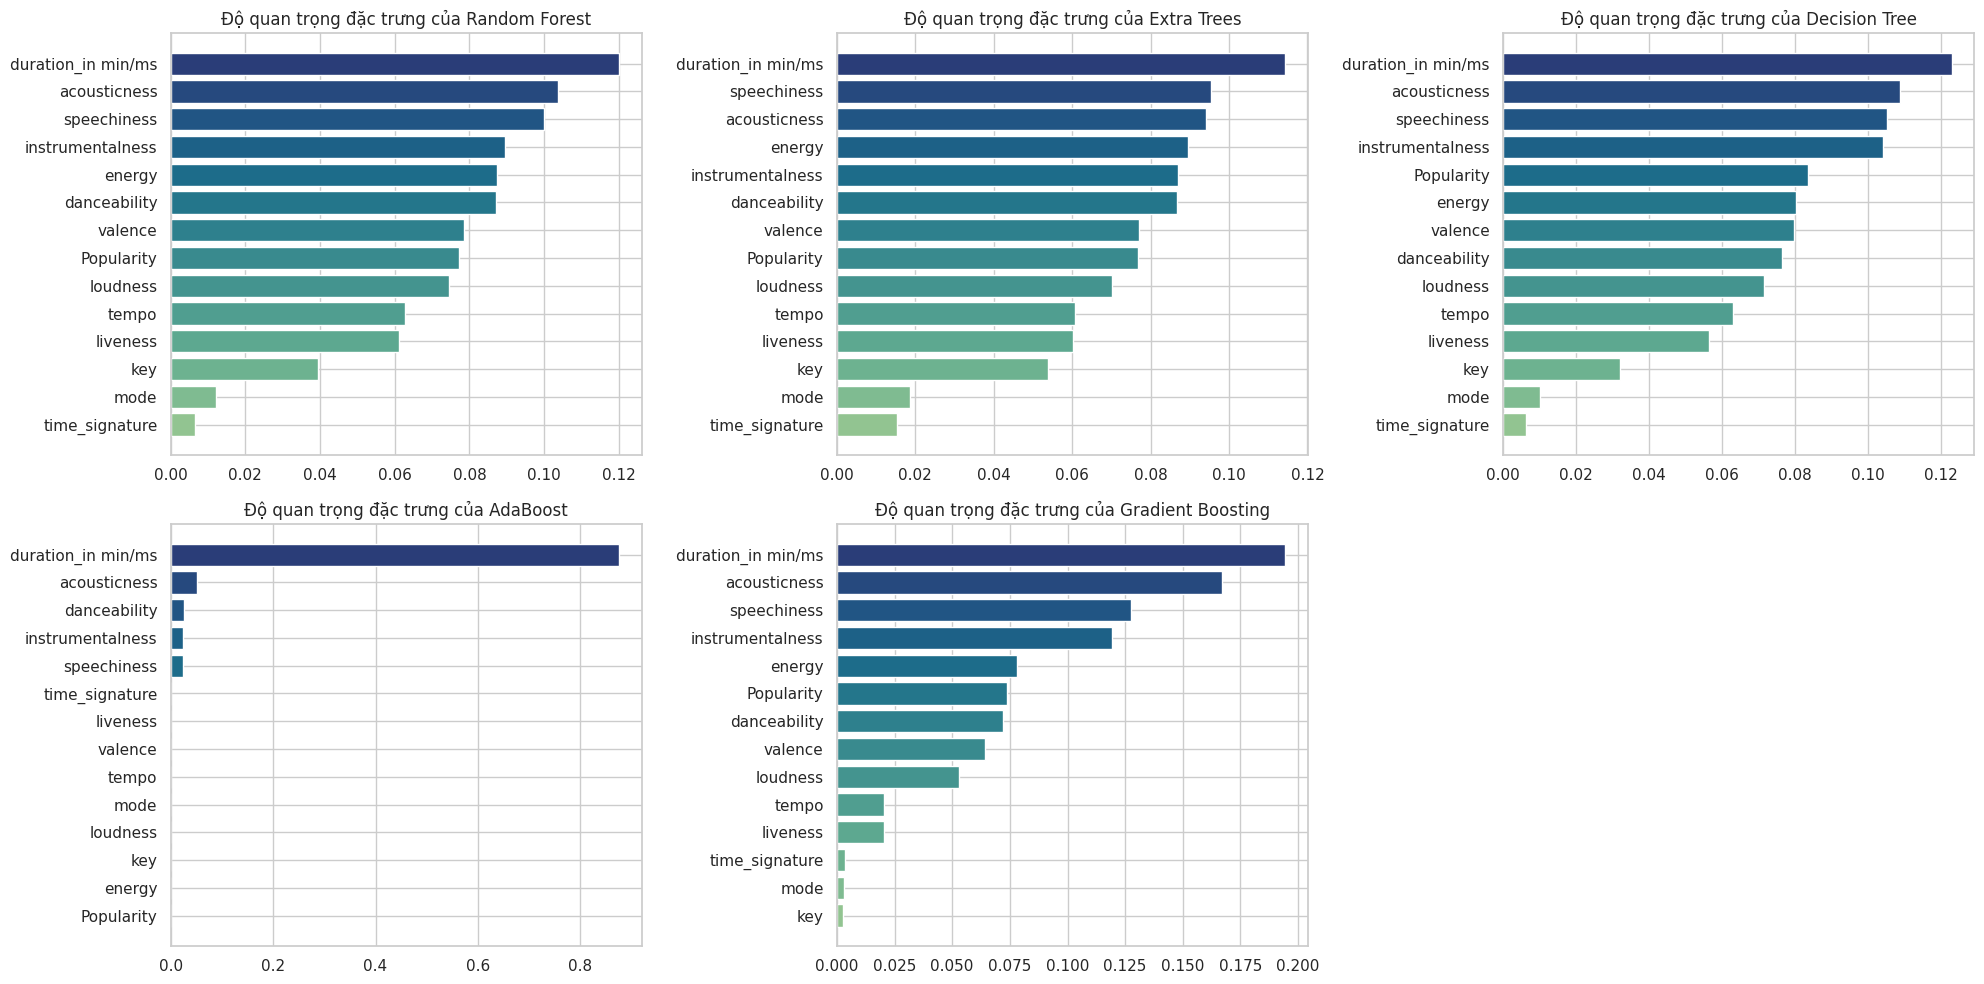

In [91]:
# Chỉ các mô hình dựa trên cây mới có feature_importances_
cay = ["Random Forest", "Extra Trees", "Decision Tree", "AdaBoost", "Gradient Boosting"]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))

for ax, k in zip(axes.ravel(), cay):
    # Lấy độ quan trọng và sắp xếp tăng dần
    imp = pd.Series(KQ[k]["model"].feature_importances_,
                    index=feature_names).sort_values()
    ax.barh(imp.index, imp.values, color=sns.color_palette("crest", len(imp)))
    ax.set_title(f"Độ quan trọng đặc trưng của {k}")

# Tắt ô thừa vì chỉ có 5 mô hình
for ax in axes.ravel()[len(cay):]:
    ax.axis("off")

fig.tight_layout()
luu(fig, "13_feature_importance")

### 3.14. Hình cây quyết định

In [92]:
# Cây gốc quá sâu nên không vẽ được, ta tạo cây phụ có độ sâu 3
dt3 = DecisionTreeClassifier(max_depth=3, random_state=42)
dt3.fit(X_tr, y_tr)

acc_dt3 = accuracy_score(y_val, dt3.predict(X_val))
print(f"Accuracy của cây độ sâu 3: {acc_dt3 * 100:.2f}%")

Accuracy của cây độ sâu 3: 37.36%


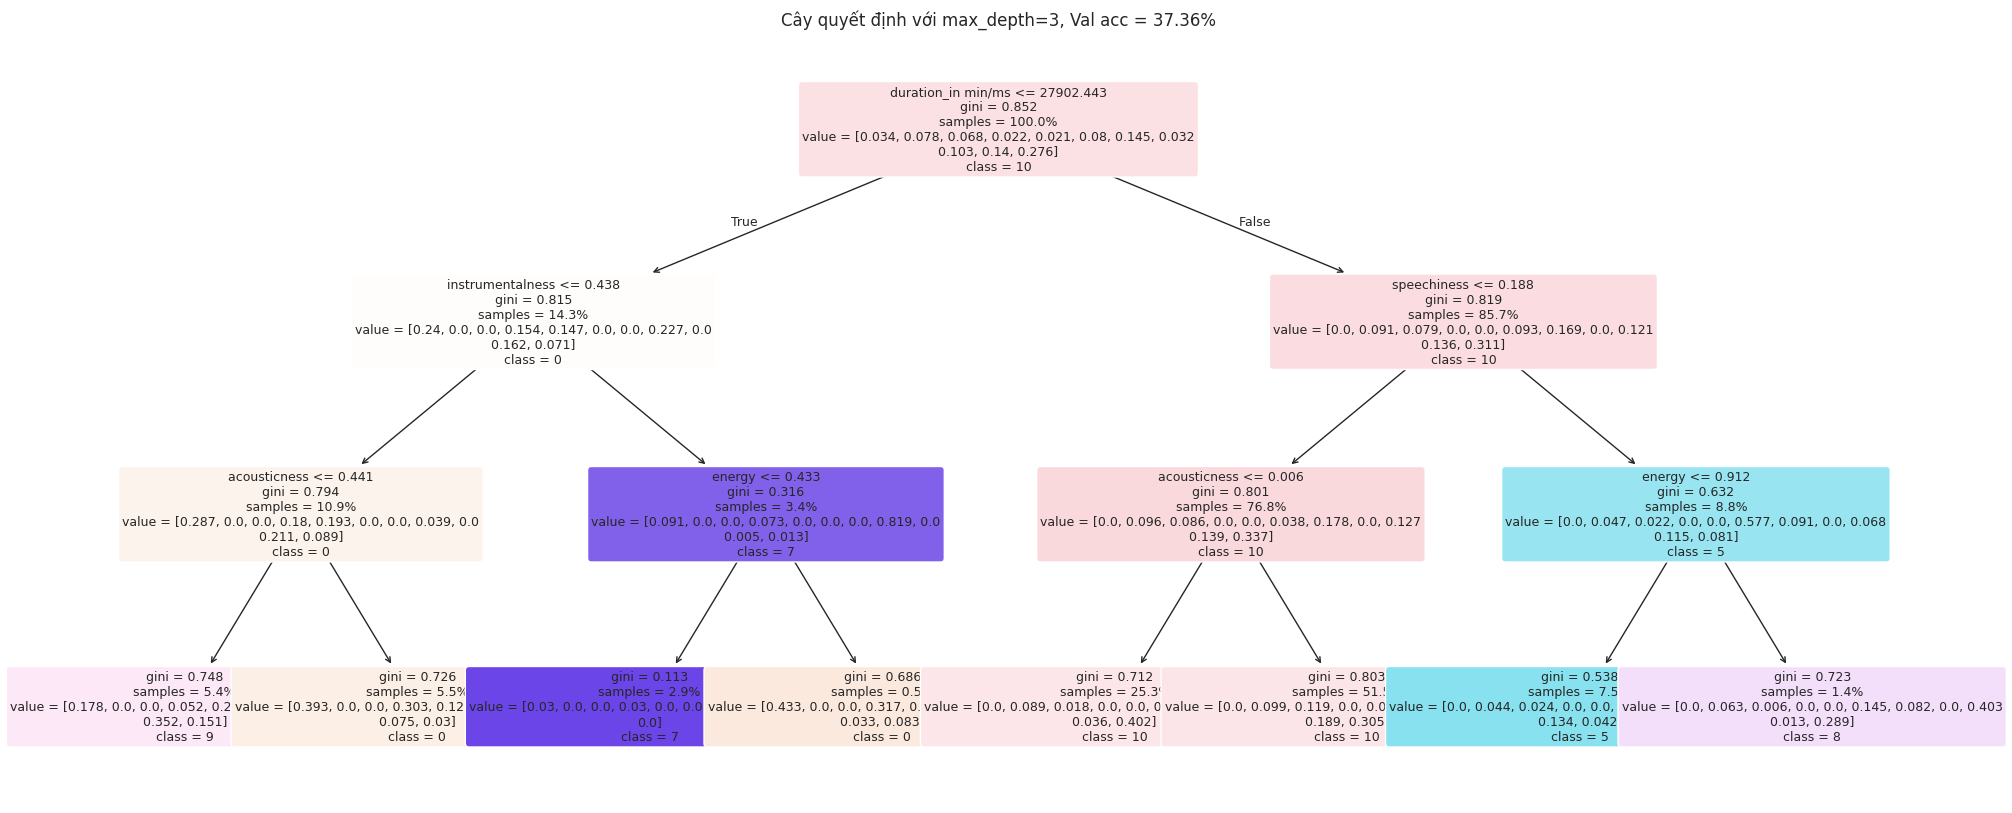

In [93]:
# Vẽ cây quyết định
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(dt3, feature_names=feature_names, class_names=ten_lop,
          filled=True, rounded=True, fontsize=9, proportion=True, ax=ax)
ax.set_title(f"Cây quyết định với max_depth=3, Val acc = {acc_dt3 * 100:.2f}%")
luu(fig, "14_decision_tree_depth3")

### 3.15. Decision Tree: ảnh hưởng của max_depth

In [94]:
# Thử độ sâu từ 1 đến 30, ghi lại accuracy train và validation
do_sau = list(range(1, 31))
a_tr = []
a_va = []

for d in do_sau:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_tr, y_tr)
    a_tr.append(m.score(X_tr, y_tr))
    a_va.append(m.score(X_val, y_val))

# Độ sâu cho accuracy validation cao nhất
best_d = do_sau[int(np.argmax(a_va))]
print("max_depth tốt nhất:", best_d)

max_depth tốt nhất: 7


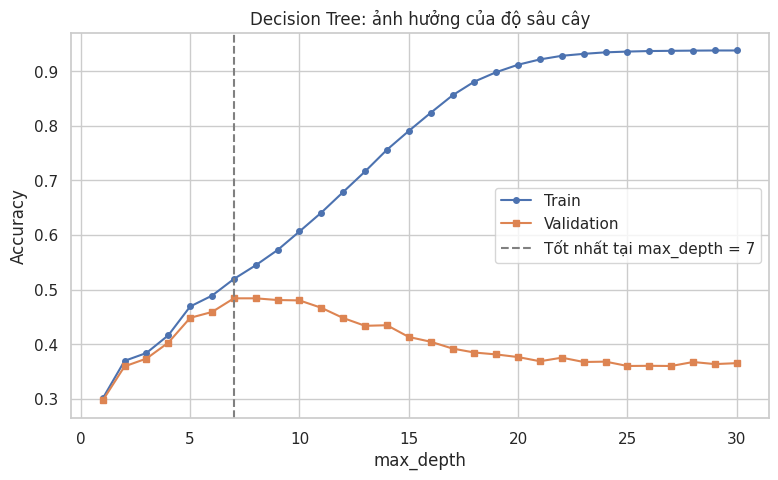

In [95]:
# Vẽ đường accuracy theo độ sâu
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(do_sau, a_tr, "o-", label="Train", ms=4)
ax.plot(do_sau, a_va, "s-", label="Validation", ms=4)
ax.axvline(best_d, ls="--", c="gray", label=f"Tốt nhất tại max_depth = {best_d}")
ax.set_xlabel("max_depth")
ax.set_ylabel("Accuracy")
ax.set_title("Decision Tree: ảnh hưởng của độ sâu cây")
ax.legend()
luu(fig, "15_dt_max_depth")

### 3.16. Random Forest: ảnh hưởng của số cây

In [96]:
# Thử các số lượng cây khác nhau
n_list = [10, 25, 50, 100, 200, 300]
a_tr = []
a_va = []

for n in n_list:
    m = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    m.fit(X_tr, y_tr)
    a_tr.append(m.score(X_tr, y_tr))
    a_va.append(m.score(X_val, y_val))
    print("Xong n_estimators =", n)

Xong n_estimators = 10
Xong n_estimators = 25
Xong n_estimators = 50
Xong n_estimators = 100
Xong n_estimators = 200
Xong n_estimators = 300


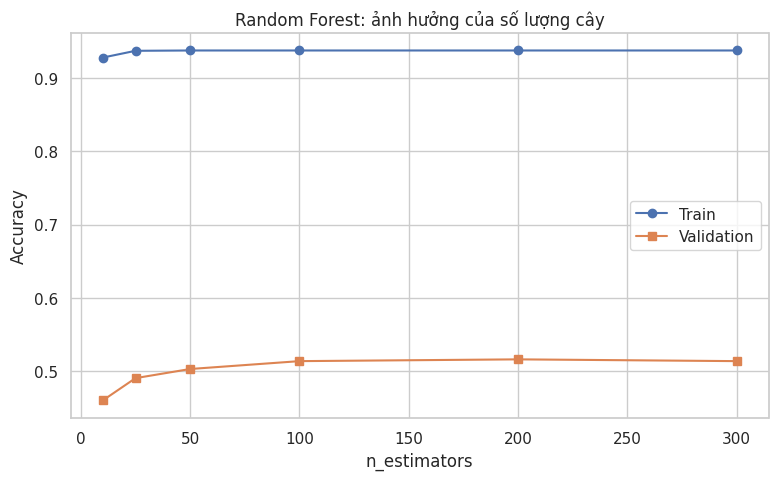

In [97]:
# Vẽ đường accuracy theo số cây
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(n_list, a_tr, "o-", label="Train")
ax.plot(n_list, a_va, "s-", label="Validation")
ax.set_xlabel("n_estimators")
ax.set_ylabel("Accuracy")
ax.set_title("Random Forest: ảnh hưởng của số lượng cây")
ax.legend()
luu(fig, "16_rf_n_estimators")

### 3.17. KNN: ảnh hưởng của k và của chuẩn hóa dữ liệu

In [98]:
# Chuẩn hóa dữ liệu về cùng thang đo
# Chỉ học tham số chuẩn hóa từ tập train
scaler = StandardScaler()
X_tr_s = scaler.fit_transform(X_tr)
X_val_s = scaler.transform(X_val)

In [99]:
# Thử k lẻ từ 1 đến 39 với dữ liệu gốc và dữ liệu đã chuẩn hóa
ks = list(range(1, 41, 2))
raw = []
sca = []

for k in ks:
    knn_a = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    knn_b = KNeighborsClassifier(n_neighbors=k).fit(X_tr_s, y_tr)
    raw.append(knn_a.score(X_val, y_val))
    sca.append(knn_b.score(X_val_s, y_val))

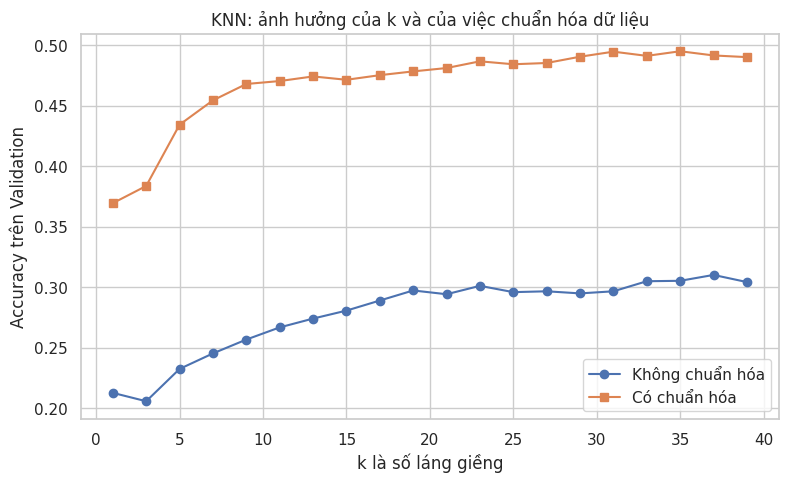

In [100]:
# Vẽ hai đường để so sánh
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(ks, raw, "o-", label="Không chuẩn hóa")
ax.plot(ks, sca, "s-", label="Có chuẩn hóa")
ax.set_xlabel("k là số láng giềng")
ax.set_ylabel("Accuracy trên Validation")
ax.set_title("KNN: ảnh hưởng của k và của việc chuẩn hóa dữ liệu")
ax.legend()
luu(fig, "17_knn_k_va_scaling")

### 3.18. MLP: đường loss và ảnh hưởng của chuẩn hóa

In [101]:
# Huấn luyện MLP hai lần, dữ liệu gốc và dữ liệu đã chuẩn hóa
mlp_raw = clone(model_mlp)
mlp_raw.fit(X_tr, y_tr)

mlp_sca = clone(model_mlp)
mlp_sca.fit(X_tr_s, y_tr)

print("Acc không chuẩn hóa:", round(mlp_raw.score(X_val, y_val) * 100, 2))
print("Acc có chuẩn hóa:", round(mlp_sca.score(X_val_s, y_val) * 100, 2))

Acc không chuẩn hóa: 21.15
Acc có chuẩn hóa: 53.33


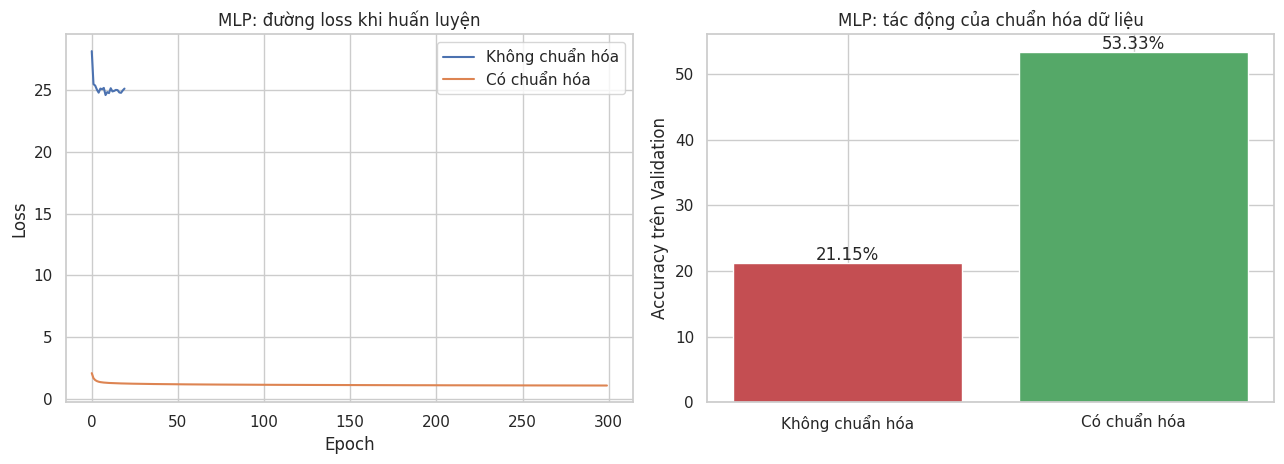

In [102]:
# Vẽ hai hình cạnh nhau, bên trái là đường loss, bên phải là accuracy
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(mlp_raw.loss_curve_, label="Không chuẩn hóa")
axes[0].plot(mlp_sca.loss_curve_, label="Có chuẩn hóa")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("MLP: đường loss khi huấn luyện")
axes[0].legend()

acc2 = [mlp_raw.score(X_val, y_val) * 100, mlp_sca.score(X_val_s, y_val) * 100]
bars = axes[1].bar(["Không chuẩn hóa", "Có chuẩn hóa"], acc2,
                   color=["#C44E52", "#55A868"])
for b in bars:
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.5,
                 f"{b.get_height():.2f}%", ha="center")
axes[1].set_ylabel("Accuracy trên Validation")
axes[1].set_title("MLP: tác động của chuẩn hóa dữ liệu")

fig.tight_layout()
luu(fig, "18_mlp_loss_va_scaling")

### 3.19. AdaBoost và Gradient Boosting: accuracy theo số vòng boosting

In [103]:
# Lấy accuracy sau mỗi vòng boosting của AdaBoost
ada = KQ["AdaBoost"]["model"]
ada_tr = list(ada.staged_score(X_tr, y_tr))
ada_va = list(ada.staged_score(X_val, y_val))

# Lấy accuracy sau mỗi vòng boosting của Gradient Boosting
gb = KQ["Gradient Boosting"]["model"]
gb_tr = [accuracy_score(y_tr, p) for p in gb.staged_predict(X_tr)]
gb_va = [accuracy_score(y_val, p) for p in gb.staged_predict(X_val)]

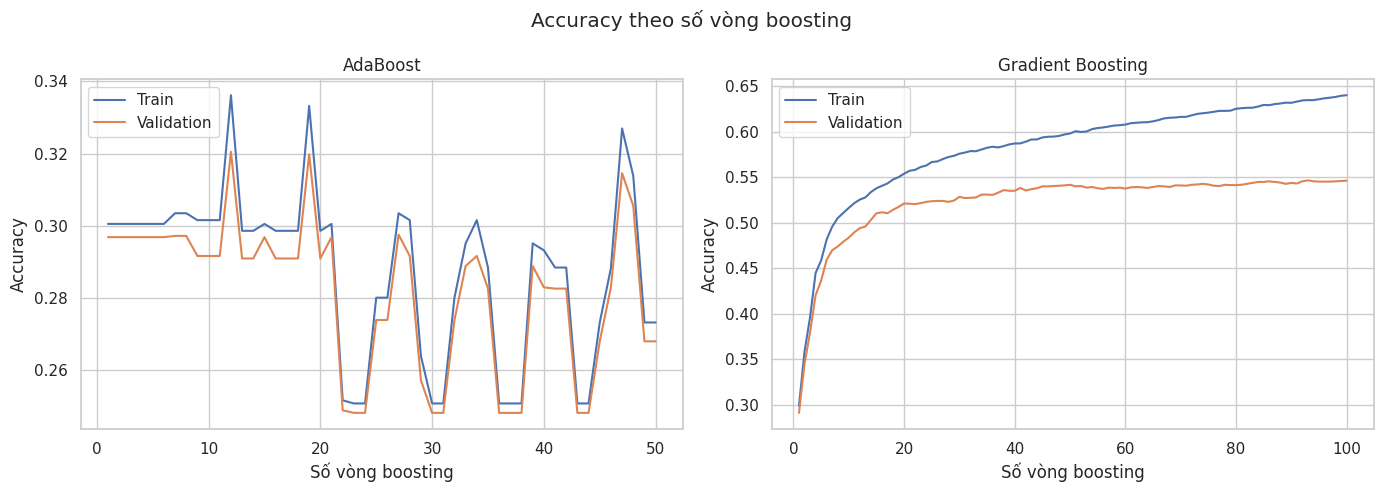

In [104]:
# Vẽ hai hình cạnh nhau, bên trái là AdaBoost, bên phải là Gradient Boosting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(ada_tr) + 1), ada_tr, label="Train")
axes[0].plot(range(1, len(ada_va) + 1), ada_va, label="Validation")
axes[0].set_xlabel("Số vòng boosting")
axes[0].set_ylabel("Accuracy")
axes[0].set_title("AdaBoost")
axes[0].legend()

axes[1].plot(range(1, len(gb_tr) + 1), gb_tr, label="Train")
axes[1].plot(range(1, len(gb_va) + 1), gb_va, label="Validation")
axes[1].set_xlabel("Số vòng boosting")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Gradient Boosting")
axes[1].legend()

fig.suptitle("Accuracy theo số vòng boosting")
fig.tight_layout()
luu(fig, "19_boosting_staged")

### 3.20. Learning curve của mô hình tốt nhất

In [105]:
# Tính learning curve với 3 fold và 6 mức kích thước dữ liệu
sizes, tr_s, va_s = learning_curve(
    clone(goc[ten_tot_nhat]), X_num_clean, y_encoded,
    cv=3, train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1
)

In [ ]:
# Vẽ learning curve kèm vùng độ lệch chuẩn
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(sizes, tr_s.mean(axis=1), "o-", c="#4C72B0", label="Train")
ax.fill_between(sizes, tr_s.mean(axis=1) - tr_s.std(axis=1),
                tr_s.mean(axis=1) + tr_s.std(axis=1), color="#4C72B0", alpha=0.15)

ax.plot(sizes, va_s.mean(axis=1), "o-", c="#DD8452", label="Cross-validation")
ax.fill_between(sizes, va_s.mean(axis=1) - va_s.std(axis=1),
                va_s.mean(axis=1) + va_s.std(axis=1), color="#DD8452", alpha=0.15)

ax.set_xlabel("Số mẫu huấn luyện")
ax.set_ylabel("Accuracy")
ax.set_title(f"Learning curve của {ten_tot_nhat}")
ax.legend()
luu(fig, "20_learning_curve")

### 3.21. Trực quan hóa dữ liệu bằng PCA

In [ ]:
# Chuẩn hóa toàn bộ dữ liệu rồi giảm xuống 2 chiều
X_all_s = StandardScaler().fit_transform(X_num_clean)

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_all_s)

print("Phương sai giải thích được:", pca.explained_variance_ratio_)

In [ ]:
# Vẽ biểu đồ phân tán, mỗi màu là một lớp
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(Z[:, 0], Z[:, 1], c=y_encoded, cmap="tab20", s=6, alpha=0.6)
ax.set_xlabel(f"PC1 {pca.explained_variance_ratio_[0]*100:.1f}%")
ax.set_ylabel(f"PC2 {pca.explained_variance_ratio_[1]*100:.1f}%")
ax.set_title("Phân bố dữ liệu theo thể loại sau khi giảm chiều bằng PCA")

# Tạo chú thích màu cho từng lớp
n_lop = len(ten_lop)
handles = []
for i in range(n_lop):
    handles.append(plt.Line2D([], [], marker="o", ls="", ms=7,
                              color=plt.cm.tab20(i / 19), label=ten_lop[i]))
ax.legend(handles=handles, title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
luu(fig, "21_pca_2d")

### 3.22. Bảng tổng hợp kết quả

In [ ]:
# Gom kết quả cuối cùng vào một bảng
tong_hop = pd.DataFrame({
    "Accuracy Train": {k: KQ[k]["acc_train"] * 100 for k in thu_tu},
    "Accuracy Validation": {k: KQ[k]["acc_val"] * 100 for k in thu_tu},
    "F1 macro": {k: df_metric.loc[k, "F1"] * 100 for k in thu_tu},
    "Thời gian huấn luyện": {k: KQ[k]["time"] for k in thu_tu},
}).round(2)

tong_hop.to_csv(f"{THU_MUC}/bang_tong_hop.csv")
display(tong_hop)
print("Đã lưu tất cả hình vào thư mục", THU_MUC)